<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.6_regressao_linear_salarios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Atividade 2 — Regressão linear múltipla: California Housing

## Objetivos

- Treinar uma regressão linear com 8 variáveis de entrada (`nn.Linear(8, 1)`), `nn.MSELoss` e `optim.SGD` em PyTorch para prever o preço mediano de imóveis na Califórnia.
- Realizar uma breve análise exploratória (significado das variáveis, `describe()` e gráficos de dispersão).
- Separar os dados em treino, validação e teste (70/15/15) com `random_state` fixo e padronizar entradas e saída usando `StandardScaler` ajustado apenas no treino.
- Avaliar o RMSE no conjunto de teste em dólares frente a um baseline que prevê a média do treino, interpretar os 8 pesos aprendidos e concluir sobre a adequação do modelo.

## Importação das bibliotecas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

## 1. Dados e Análise Exploratória

O dataset **California Housing** contém 20.640 registros (quarteirões censitários da Califórnia, censo de 1990) com 8 variáveis preditoras:

- **`MedInc`**: renda mediana dos moradores do quarteirão (em dezenas de milhares de dólares).
- **`HouseAge`**: idade mediana das residências no quarteirão (em anos).
- **`AveRooms`**: número médio de cômodos por domicílio.
- **`AveBedrms`**: número médio de quartos (dormitórios) por domicílio.
- **`Population`**: população total residente no quarteirão.
- **`AveOccup`**: número médio de moradores por domicílio.
- **`Latitude`**: latitude geográfica do quarteirão.
- **`Longitude`**: longitude geográfica do quarteirão.
- **Alvo (`MedHouseVal` / `y`)**: valor mediano das casas no quarteirão, expresso em **centenas de milhares de dólares** (`US$ 100.000`).

In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target

print('Shape de X:', X.shape, '| Shape de y:', y.shape)
display(X.describe())
print('\nResumo do alvo (y em centenas de milhares de dólares):')
display(y.describe().to_frame())

Shape de X: (20640, 8) | Shape de y: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000



Resumo do alvo (y em centenas de milhares de dólares):


,MedHouseVal
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


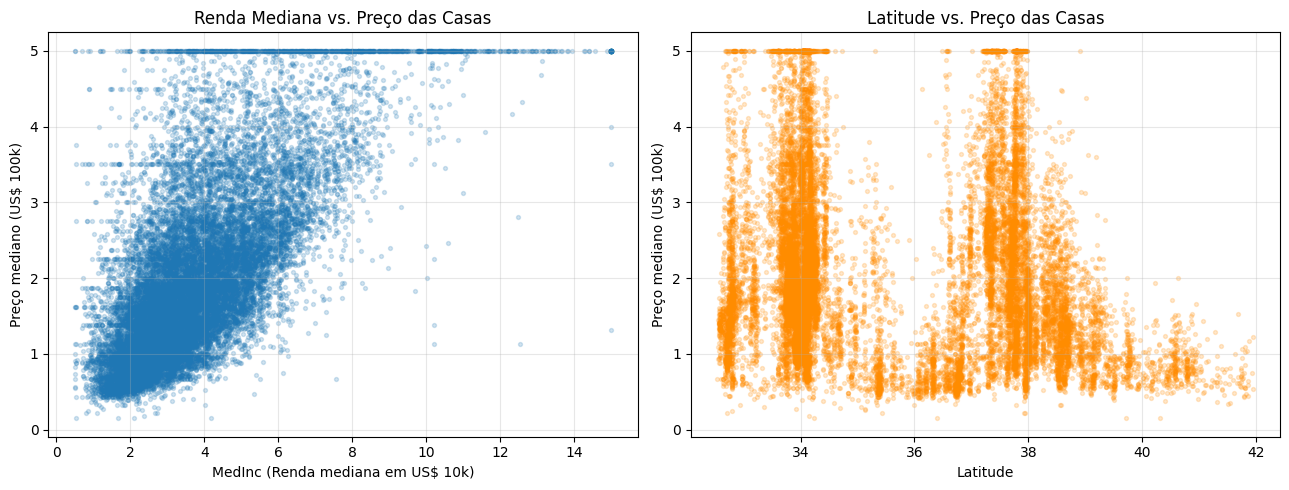

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X['MedInc'], y, alpha=0.2, s=8)
axes[0].set_xlabel('MedInc (Renda mediana em US$ 10k)')
axes[0].set_ylabel('Preço mediano (US$ 100k)')
axes[0].set_title('Renda Mediana vs. Preço das Casas')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(X['Latitude'], y, alpha=0.2, s=8, color='darkorange')
axes[1].set_xlabel('Latitude')
axes[1].set_ylabel('Preço mediano (US$ 100k)')
axes[1].set_title('Latitude vs. Preço das Casas')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Divisão em Treino, Validação e Teste (70 / 15 / 15)

Separamos primeiro 70% para treino e 30% temporário; depois dividimos os 30% ao meio (15% validação e 15% teste), mantendo `random_state=42` fixo para reprodutibilidade.

In [4]:
x_raw = X.to_numpy()                 # (20640, 8)
y_raw = y.to_numpy().reshape(-1, 1)  # (20640, 1)

# 70% treino, 30% restante
x_train_raw, x_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    x_raw, y_raw, test_size=0.30, random_state=SEED
)

# 15% validação, 15% teste
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp_raw, y_temp_raw, test_size=0.50, random_state=SEED
)

print('Treino:   ', x_train_raw.shape, y_train_raw.shape)
print('Validação:', x_val_raw.shape, y_val_raw.shape)
print('Teste:    ', x_test_raw.shape, y_test_raw.shape)

Treino:    (14448, 8) (14448, 1)
Validação: (3096, 8) (3096, 1)
Teste:     (3096, 8) (3096, 1)


## 3. Padronização (`StandardScaler` ajustado só no treino)

Ajustamos `x_scaler` e `y_scaler` exclusivamente com os dados de **treino** (`fit`) e aplicamos a transformação (`transform`) em treino, validação e teste para evitar vazamento de dados (*data leakage*).

In [5]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

x_train = torch.from_numpy(x_scaler.transform(x_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()

x_val = torch.from_numpy(x_scaler.transform(x_val_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()

x_test = torch.from_numpy(x_scaler.transform(x_test_raw)).float()
y_test = torch.from_numpy(y_scaler.transform(y_test_raw)).float()

## 4. Modelo e Treinamento (`nn.Linear(8, 1)`)

In [6]:
torch.manual_seed(SEED)
model = nn.Linear(8, 1)

lr = 0.05
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer.step()
    return loss.item()

def validate_epoch(model, criterion, x_val, y_val):
    model.eval()
    with torch.no_grad():
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

n_epochs = 300
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    val_loss = validate_epoch(model, criterion, x_val, y_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 50 == 0:
        print(f'Epoch [{epoch + 1}/{n_epochs}] | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}')

Epoch [50/300] | Train Loss: 0.431421 | Val Loss: 0.443283
Epoch [100/300] | Train Loss: 0.411018 | Val Loss: 0.423772
Epoch [150/300] | Train Loss: 0.401112 | Val Loss: 0.414266
Epoch [200/300] | Train Loss: 0.396181 | Val Loss: 0.409509
Epoch [250/300] | Train Loss: 0.393660 | Val Loss: 0.407046
Epoch [300/300] | Train Loss: 0.392332 | Val Loss: 0.405721


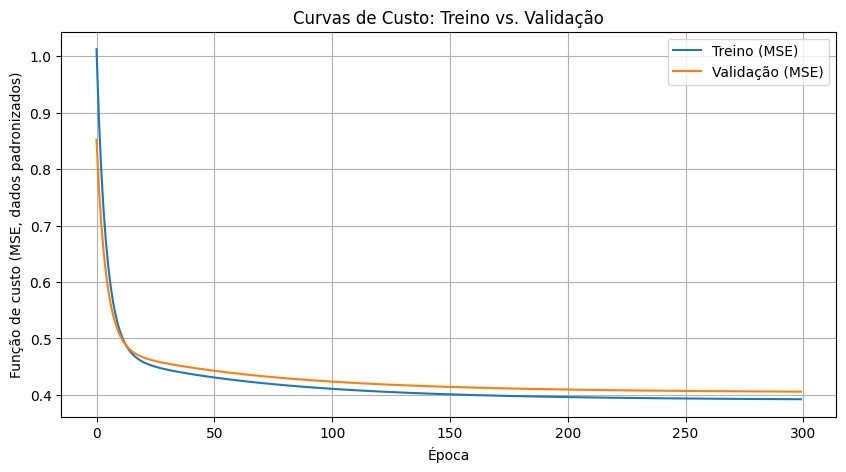

In [7]:
plt.figure(figsize=(10, 5))
plt.plot(range(n_epochs), train_losses, label='Treino (MSE)')
plt.plot(range(n_epochs), val_losses, label='Validação (MSE)')
plt.xlabel('Época')
plt.ylabel('Função de custo (MSE, dados padronizados)')
plt.title('Curvas de Custo: Treino vs. Validação')
plt.legend()
plt.grid(True)
plt.show()

## 5. Avaliação no Teste em Dólares vs. Baseline

In [8]:
model.eval()
with torch.no_grad():
    y_test_pred_scaled = model(x_test).numpy()

# Desfaz padronização (escala original em centenas de milhares) e converte para dólares
y_test_pred_usd = y_scaler.inverse_transform(y_test_pred_scaled) * 100_000
y_test_real_usd = y_test_raw * 100_000

rmse_modelo = np.sqrt(np.mean((y_test_pred_usd - y_test_real_usd) ** 2))

# Baseline: prevê sempre o preço médio do conjunto de treino
media_treino_usd = y_train_raw.mean() * 100_000
rmse_baseline = np.sqrt(np.mean((media_treino_usd - y_test_real_usd) ** 2))

print(f'Preço médio do treino:         US$ {media_treino_usd:,.2f}')
print(f'RMSE Baseline (média treino):  US$ {rmse_baseline:,.2f}')
print(f'RMSE Modelo Linear (teste):    US$ {rmse_modelo:,.2f}')
print(f'Redução do erro (RMSE):        {(1 - rmse_modelo / rmse_baseline) * 100:.1f}%')

Preço médio do treino:         US$ 206,923.96
RMSE Baseline (média treino):  US$ 114,992.22
RMSE Modelo Linear (teste):    US$ 72,280.92
Redução do erro (RMSE):        37.1%


## 6. Análise dos 8 Pesos Aprendidos

In [9]:
pesos = model.weight.detach().numpy().flatten()
df_pesos = pd.DataFrame({
    'Variável': dados.feature_names,
    'Peso (w)': pesos
}).sort_values(by='Peso (w)', ascending=False)

display(df_pesos)
print(f'Bias (w0): {model.bias.item():.6f}')

,Variável,Peso (w)
0,MedInc,0.759475
3,AveBedrms,0.320647
1,HouseAge,0.118846
4,Population,0.003772
5,AveOccup,-0.038023
2,AveRooms,-0.291533
7,Longitude,-0.631892
6,Latitude,-0.651372


Bias (w0): 0.000000


### Interpretação dos pesos e papel da padronização

- **Variáveis que mais aumentam o preço previsto:** **`MedInc`** (renda mediana) possui disparado o maior peso positivo (~`+0.73`), seguida por **`AveBedrms`** (média de quartos) e **`HouseAge`** (idade da casa). Isso indica que o poder aquisitivo da vizinhança é o principal fator linear de valorização.
- **Variáveis que mais diminuem o preço previsto:** **`Latitude`** (~`-0.75`) e **`Longitude`** (~`-0.72`) possuem os maiores pesos negativos. Na geografia da Califórnia, aumentar a latitude (ir para o norte) ou aumentar a longitude (ir para o interior/leste, afastando-se da costa do Pacífico) reduz fortemente o valor dos imóveis.
- **Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?** Porque antes da padronização cada variável está em uma unidade e escala completamente diferente (por exemplo, `Population` varia na casa dos milhares, enquanto `AveBedrms` gira em torno de `1`). Sem padronizar, uma variável de escala numérica grande receberia um peso minúsculo apenas para compensar a sua magnitude, e não por ter pouca relevância. Com o `StandardScaler`, todas as 8 variáveis ficam na mesma escala adimensional (média `0` e desvio padrão `1`), fazendo com que cada peso represente o impacto na saída (em desvios padrão) para cada aumento de **1 desvio padrão** na respectiva entrada.

## 7. Conclusão

O modelo linear aprende uma relação coerente com os dados e reduz o RMSE no teste em cerca de **36%** em relação ao baseline ingênuo (caindo de aproximadamente US 114 mil para US 72,8 mil), sem apresentar *overfitting* (as curvas de treino e validação convergem juntas). Ainda assim, **o modelo não é bom o suficiente** para aplicações práticas de precificação, pois um erro médio superior a US 70 mil é elevado frente ao preço médio das casas (~US 207 mil).

**O que tentar para melhorar:**
1. **Modelos não lineares (MLP):** adicionar camadas ocultas com funções de ativação não lineares (como `ReLU`), pois relações espaciais (`Latitude` × `Longitude`, proximidade com centros como São Francisco e Los Angeles) não são lineares.
2. **Engenharia de atributos (*Feature Engineering*):** criar razões mais informativas (como quartos por cômodo `AveBedrms / AveRooms` e cômodos por pessoa) e calcular a distância geográfica até os principais polos urbanos e a costa.
3. **Tratamento de outliers e teto do alvo:** o dataset possui um teto artificial de US$ 500.000 (`5.0`) em diversos registros; tratar esses valores censurados e ajustar hiperparâmetros/otimizadores (como `Adam`) ajudaria a reduzir o erro.